# E80: Can VPD's adversary fail do-nothing on Qwen3-1.7B, and pass a good placement?

*2026-11-04, D1, `qwen-decomp-lead`. D1 is a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement. Record: `reports/analyses/2026-11-04_analysis_e80-adversary.md`.*

Independent check: pending.

**The answer.** By the filed rule the outcome is "D1 has a test and a first candidate". It is worth little as yet. The adversary reads the state with the whole update left outside the subcomponents above the unchanged decomposition, about a third higher. But that same empty state sits under the pass bar, and the placements read closer to it than two starts on the unchanged decomposition read to each other. So nothing here shows that any placement is good.

**Something unexpected happened that I cannot explain.** We leaned, at medium strength, that do-nothing would read within the band. It read 1.317 times the unchanged decomposition, over a bar of 1.19, which reverses the lean. Our weak lean that the in-span state passes held. No cause is claimed.


## What we were trying to test

An update changes a model's weights, and D1 asks for a map that moves the decomposition along with it and a test that can fail a bad map. E79 removed the own-mask read as that test: leaving the whole update out of the subcomponents read as well as the best trained change. This job asks whether VPD's own adversary does better.

**The adversary.** W0 is Qwen3-1.7B before the update, and the fine-tuned model is W0 plus δW, ten steps of a fine-tune on maths rows. Each weight matrix is written as rank-one subcomponents plus a leftover Δ. Γ gives each subcomponent a causal importance $g$ from 0 to 1 on each token, reading the state's own weights with its parameters fixed. The adversary gives each subcomponent a setting $s$, shared over all rows and positions, and uses it at strength $m = g + (1-g)s$. It also picks how much of Δ to keep per matrix. From a random start it takes 20 sign steps up the KL from the state's own clean output to its masked output. Zero means the attack changed nothing. The ratio is a state's read over W0's read at seed 0, so W0 reads 1.

**The states, and what each rules out.**

- **W0**, the control, at two seeds. It sets the band, and on FineWeb rows it reproduces an earlier job.
- **Do-nothing**, the worst placement by rule: the fine-tuned weights, components unmoved, the whole update in Δ. If the adversary reads it near W0, no read here can fail anything.
- **In-span**, the candidate: the least-squares split's change to the subcomponents, its remainder discarded.
- **A**, the clean-term change: E76's teacher training on the clean term alone. What its components hold sits further from the fine-tuned weights than W0's components do.

**The rows.** The rule reads 64 maths rows of 256 tokens, unused by any earlier arm. W0 and do-nothing are also read on 128 FineWeb rows of 512 tokens, as read, under no rule.

## What we expected, and why

We leaned, at medium strength, that do-nothing would read within the band, because masks alone already reach near the fine-tuned output with Δ off. We leaned weakly that in-span would pass, since its clean output sits near the fine-tuned one. The rules: do-nothing fails above 1 plus the band, which is W0's start gap with a floor of 0.19. In-span and A pass at or under 1.40, fail at or over 1.61, and read "no call" between. Those two bars were filed on the 67M model in E71.

## What we observed

The controls held, and no stage stopped. W0 on FineWeb rows read 1.75, inside the window of 1.36 to 2.04 around the earlier job's 1.70.

### Does the adversary read do-nothing above W0, and do the bars separate it from the placements?


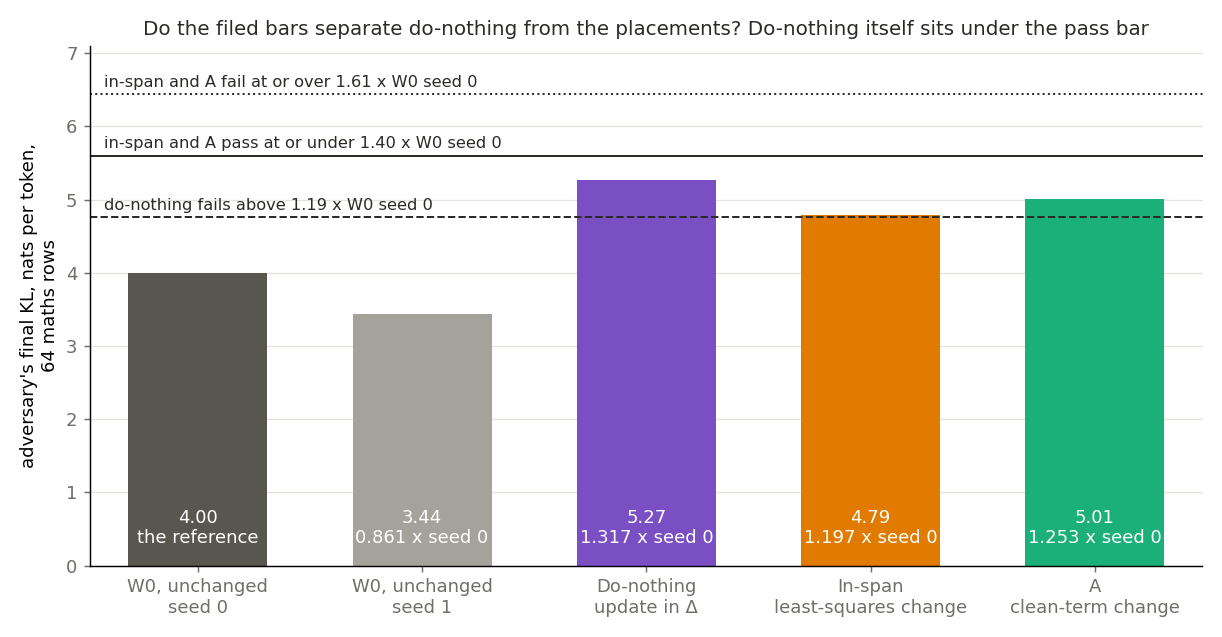

| maths rows | final KL | over W0 seed 0 | over W0 seed 1 | filed verdict |
|---|---|---|---|---|
| W0, seed 0 | 4.00 | 1 | 1.16 | reference |
| W0, seed 1 | 3.44 | 0.861 | 1 | sets the band |
| do-nothing | 5.27 | 1.317 | 1.53 | fails do-nothing |
| in-span | 4.79 | 1.197 | 1.39 | passes |
| A | 5.01 | 1.253 | 1.46 | passes, for report |

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_d1_adversary")
RES, FIG = ROOT / "results", ROOT / "figures"
R = json.loads((RES / "results.json").read_text())
KL = {k: v["kl"] for k, v in R["starts"].items()}
S = R["score"]
W0, W1 = KL["W0_M_s0"], KL["W0_M_s1"]

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

show("adversary_maths.png")
table(["maths rows", "final KL", "over W0 seed 0", "over W0 seed 1", "filed verdict"],
      [["W0, seed 0", f"{W0:.2f}", 1, f"{W0 / W1:.2f}", "reference"], ["W0, seed 1", f"{W1:.2f}", f"{W1 / W0:.3f}", 1, "sets the band"]]
      + [[name, f"{KL[k + '_M_s0']:.2f}", f"{S['r'][k]:.3f}", f"{KL[k + '_M_s0'] / W1:.2f}", v]
         for name, k, v in (("do-nothing", "N", S["do_nothing"]), ("in-span", "I", S["inspan"]), ("A", "A", S["A"] + ", for report"))])


**Reading it.** Do-nothing reads above W0 at both W0 starts, and the bars do not separate it from the placements. Do-nothing reads 5.27 against W0's 4.00 and 3.44. On FineWeb rows, under no rule, it reads 2.25 against 1.75. So by the filed rule the outcome is "D1 has a test and a first candidate", and it stands.

The caveat decides how much that outcome is worth, because the filed bars do not cohere. Do-nothing's 1.317 is itself under the in-span pass bar of 1.40. In-span's 1.197 is over do-nothing's fail bar of 1.19, by 0.007. Do-nothing and in-span differ by about 10%, less than W0's own start-to-start 16%, and each has one start. So this run shows the adversary reads do-nothing above W0. It does not show that it reads in-span below do-nothing, nor that in-span is a good placement, and the ordering of the three is not read as a result. Against W0's second start the ratios rise: do-nothing 1.53, A 1.46, in-span 1.39.

The bars stand as filed; this is a reading beside them. No cause is claimed for do-nothing's rise: this job does not separate Δ carrying behaviour from a change in which subcomponents Γ switches on, or from anything else.

### Does the read follow how much of the update the components hold?


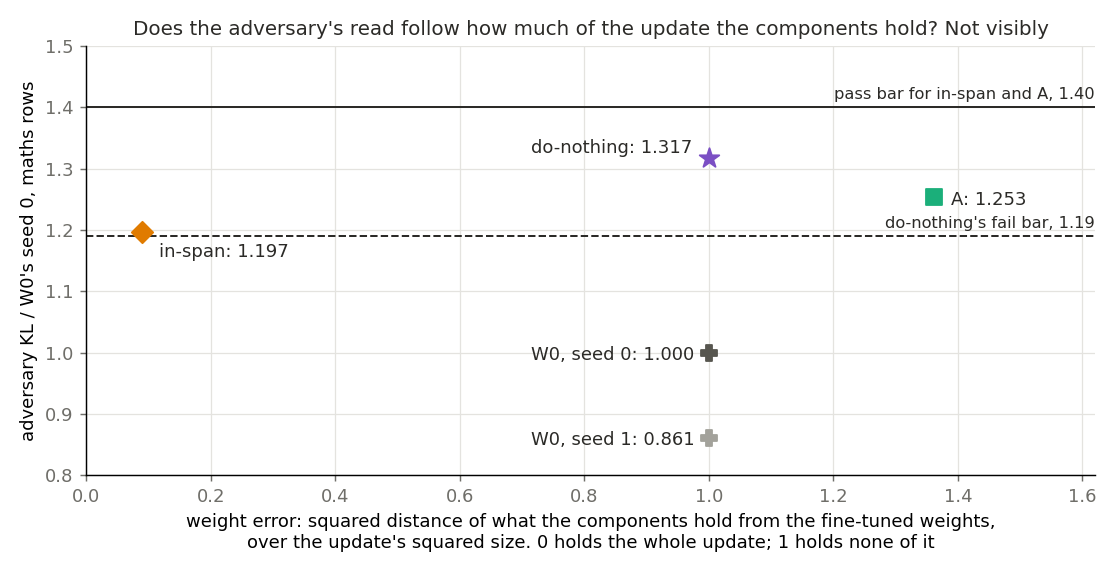

| state | weight error | ratio | clean KL to fine-tuned | self, E79's maths rows |
|---|---|---|---|---|
| W0 | 1 | 1 | 1.842 | 0.043 |
| do-nothing | 1.00 | 1.317 | about 0 | 0.066, E79 |
| in-span | 0.09 | 1.197 | 0.0094 | 0.062 |
| A | 1.36 | 1.253 | 0.012, E76 | 0.065, E79 |

In [2]:
show("weight_error.png")
w = R["weights"]
table(["state", "weight error", "ratio", "clean KL to fine-tuned", "self, E79's maths rows"],
      [["W0", 1, 1, f"{R['own']['W0']['M']['clean']:.3f}", f"{R['own']['W0']['M']['self']:.3f}"],
       ["do-nothing", f"{w['N']:.2f}", f"{S['r']['N']:.3f}", "about 0", "0.066, E79"],
       ["in-span", f"{w['I']:.2f}", f"{S['r']['I']:.3f}", f"{R['own']['I']['M']['clean']:.4f}", f"{R['own']['I']['M']['self']:.3f}"],
       ["A", f"{w['A']:.2f}", f"{S['r']['A']:.3f}", "0.012, E76", "0.065, E79"]])


**Reading it.** Not visibly, on these three states. Weight error is the squared distance of what the components hold from the fine-tuned weights, over the update's squared size: 0 holds the whole update, 1 holds none. In-span reads 0.09 and a ratio of 1.197. Do-nothing reads 1 and 1.317. A reads 1.36, worse than do-nothing, and its ratio of 1.253 passes the same bar as the candidate. Three points with one start each cannot show a trend or the lack of one, so this says only that the read has not yet been shown to grade placement.

### Had the search finished, and how steady is one read?


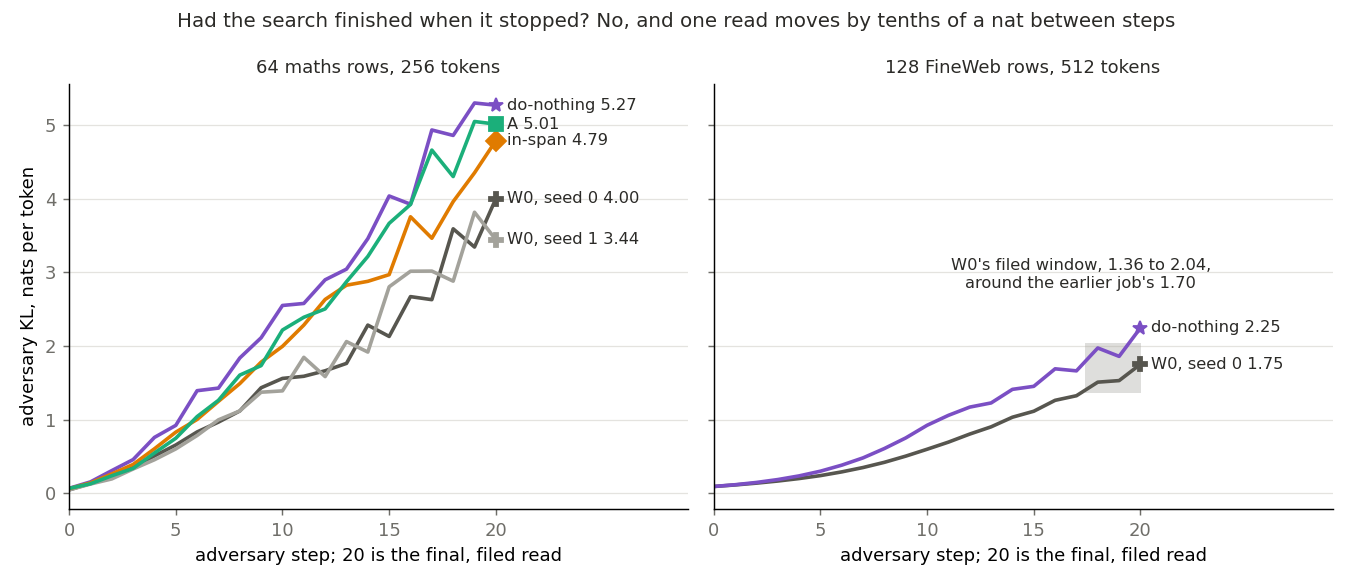

In [3]:
show("steps.png")


**Reading it.** The search had not finished, so every read is a lower bound. On FineWeb rows W0 was rising about 9.5% per step over its last five steps, and do-nothing about 9%. Maths rows also move by tenths of a nat between neighbouring steps: W0's seed 0 rose 0.66 at its last step and seed 1 fell 0.37, which swaps the two starts. That last move is larger than the gap between do-nothing and in-span, 0.48. The filed read is the final one, and it stands.

## What we learned

Under E79's own-mask read against the fine-tuned model, do-nothing read lowest of all. Under the adversary it reads above W0 beyond the filed band on maths rows, so the adversary may be able to mark do-nothing as worse than the unchanged decomposition. It is not yet a test that fails a bad placement while passing a good one: in-span and A are not separated from do-nothing. In-span's clean KL of 0.0094 and weight error of 0.09 are good readings by other measures, not evidence from the adversary. So the filed outcome gives D1 a first candidate by label only, and whether the adversary grades placement remains open.

## How compelling is the evidence

Weak beyond the first claim. There is one update and one seed of each state other than W0, so do-nothing, in-span and A have no spread. The adversary is a lower bound, still rising at step 20 on FineWeb rows. The maths rows are not on the 128-row scale, because a shared setting has fewer rows to satisfy, so their reads compare only with each other. The job has no state known to fail on this model, so nothing yet shows the bars' power. The read is blind to which subcomponents carry the update.

## Surprises

The reversal leads: the medium lean said do-nothing would read within the band, and it read over the bar. I cannot explain it. Beside that, A's weight error of 1.36 did not stop it passing, and W0's two starts swap order at the last step.

## What next

**A proposal, not a result: repeat starts paired by seed, on the same rows,** to find whether do-nothing and in-span separate. If they separate by more than the paired spread, the adversary may grade placement. If not, it tells do-nothing from W0 only, and D1 still lacks a test that passes a good placement over a bad one. Details come from the lead.

## Scorecard


In [4]:
table(["id", "claim", "rule", "read", "verdict"], [
    ["stage 1", "W0 on W reproduces the earlier job", "1.36 to 2.04", f"{KL['W0_W_s0']:.3f}", "in the window" if S["stage1_in_window"] else "outside"],
    ["do_nothing", "the adversary fails do-nothing", f"r(N) > 1 + {S['b']}", f"{S['r']['N']:.3f}", f"\"{S['do_nothing']}\"; medium lean \"within the band\" reversed"],
    ["inspan", "the adversary passes in-span", "r(I) ≤ 1.40 passes, ≥ 1.61 fails", f"{S['r']['I']:.3f}", f"\"{S['inspan']}\"; weak lean held"],
    ["A", "same bars, for report", "as in-span", f"{S['r']['A']:.3f}", f"\"{S['A']}\""],
    ["outcome", "fails do-nothing and in-span passes", "as filed", "", f"\"{S['outcome']}\", stands as filed"],
    ["W", "reported as read", "none", f"r(N) {S['W_as_read']['r_N']:.3f}", "as read"],
])


| id | claim | rule | read | verdict |
|---|---|---|---|---|
| stage 1 | W0 on W reproduces the earlier job | 1.36 to 2.04 | 1.752 | in the window |
| do_nothing | the adversary fails do-nothing | r(N) > 1 + 0.19 | 1.317 | "fails do-nothing"; medium lean "within the band" reversed |
| inspan | the adversary passes in-span | r(I) ≤ 1.40 passes, ≥ 1.61 fails | 1.197 | "passes"; weak lean held |
| A | same bars, for report | as in-span | 1.253 | "passes" |
| outcome | fails do-nothing and in-span passes | as filed |  | "D1 has a test and a first candidate", stands as filed |
| W | reported as read | none | r(N) 1.282 | as read |

## Departures from the literature

The adversary follows VPD's evaluation config. Departures, in full in the report:

- **A changed model.** VPD runs it on the model its decomposition was fitted to. Here Γ is frozen and reads weights it was not fitted to.
- **Rows.** VPD's evaluation here uses 128 rows of 512 tokens. The rule reads 64 maths rows of 256 tokens.
- **Ratio and bars.** VPD reports the KL alone. The ratio, the 1.40, the 1.61 and the 0.19 are this project's, the first two carried unchanged from the 67M model.
- **One start per state, final step only.** The filed rule's choice.
- **Precision.** Components in fp32 and Γ in bf16, as the earlier job. The authors' bf16 autocast cannot hold these moved columns.
- **The placements.** The least-squares split and teacher training have no published source. In-span discards the remainder where `GOALS.md`'s split sends it to Δ.

## Not run

1. A second start of do-nothing, in-span or A, or a paired spread at the same seeds.
2. In-span and A on FineWeb rows.
3. Any state known to be a bad placement of the right size.
4. More than 20 steps, so the plateau is unknown.
5. Other updates, steps or tasks, and maths rows at the 128-row scale.
6. Which subcomponents the attack or the update uses.

## Provenance

Results `experiments/qwen_d1_adversary/results/`, figures from `plot.py`. One RunPod H100 PCIe, 1.94 h of run from the log, peak GPU 66.1 GB, about $8 at the plan's rate. No amendments used.
